# Transfer Test: Golmud Solar Park

The model trained on Talatan (2020) is applied unchanged to a second large solar park on the Tibetan Plateau: the Golmud desert cluster, about 450 km west of Talatan, also in Qinghai. It shows how well the model transfers to a park it has never seen, with other developers, module types and layouts.

The notebook has two parts:

1. **Scene download** for the study area, followed by a preview. The hand labels are then digitised in QGIS on this scene.
2. **Analysis** once the labels exist: prediction, accuracy against the labels, PV area and error map, with exactly the same steps and settings as for Talatan in notebook 04.

## Setup

In [1]:
import sys
from pathlib import Path

import geoai
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

sys.path.append("../scripts")
from preprocessing import BASELINE_OFFSET, scale_to_byte
from scene_search import download_scene, search_scenes

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
SCENE_DIR = DATA_DIR / "raw" / "raster" / "sentinel2"
VECTOR_DIR = DATA_DIR / "raw" / "vectors"
SCALED_DIR = DATA_DIR / "processed" / "scaled"
MODEL_DIR = BASE_DIR / "models"
PREDICTIONS_DIR = BASE_DIR / "results" / "predictions"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"
FIGURES_DIR = BASE_DIR / "results" / "figures"

SITE = "golmud"
SCENE_DAY = "2026-11-06"

# Study area [min_lon, min_lat, max_lon, max_lat] in WGS84: extent of the hand labels
# plus a margin of 1.5 km, the same margin as around Talatan in notebook 05
GOLMUD_BBOX = [95.074, 36.309, 95.292, 36.438]
CRS = "EPSG:32646"   # WGS 84 / UTM zone 46N: Golmud lies at about 95° E, Talatan in zone 47N

raw_scene = SCENE_DIR / f"{SITE}_{SCENE_DAY}.tif"
scene = SCALED_DIR / f"{SITE}_{SCENE_DAY}_scaled.tif"
label_path = VECTOR_DIR / f"{SITE}_labels_{SCENE_DAY}.shp"
mask_path = PREDICTIONS_DIR / f"prediction_{SITE}_{SCENE_DAY}.tif"
probability_path = PREDICTIONS_DIR / f"probability_{SITE}_{SCENE_DAY}.tif"

MODEL_FILE = "talatan_unet.pth"
NUM_CHANNELS = 6

for folder in (SCENE_DIR, VECTOR_DIR, SCALED_DIR, PREDICTIONS_DIR, EVALUATION_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## Part 1: Scene Download

The scene is searched for the chosen day only. The tile-wide cloud filter is switched off, because the clouds over the park itself are checked on the preview.

In [2]:
found = search_scenes(GOLMUD_BBOX, SCENE_DAY, SCENE_DAY, max_cloud=100)
if not found:
    raise ValueError(f"No scene on {SCENE_DAY} covers the whole study area")

day = found[0]
baseline = day["items"][0].properties.get("s2:processing_baseline", "?")
print(f"{day['day']} | coverage {day['coverage']:.2f} | tile cloud cover {day['clouds']:.1f} % | baseline {baseline}")

download_scene(day["items"], GOLMUD_BBOX, raw_scene, crs=CRS)
print(f"Saved: {raw_scene}")

2026-11-06 | coverage 1.00 | tile cloud cover 0.2 % | baseline 05.13


Saved: /Users/fabianott/Desktop/sds320/project/data/raw/raster/sentinel2/golmud_2026-11-06.tif


1990 x 1477 pixels, 19.9 x 14.8 km


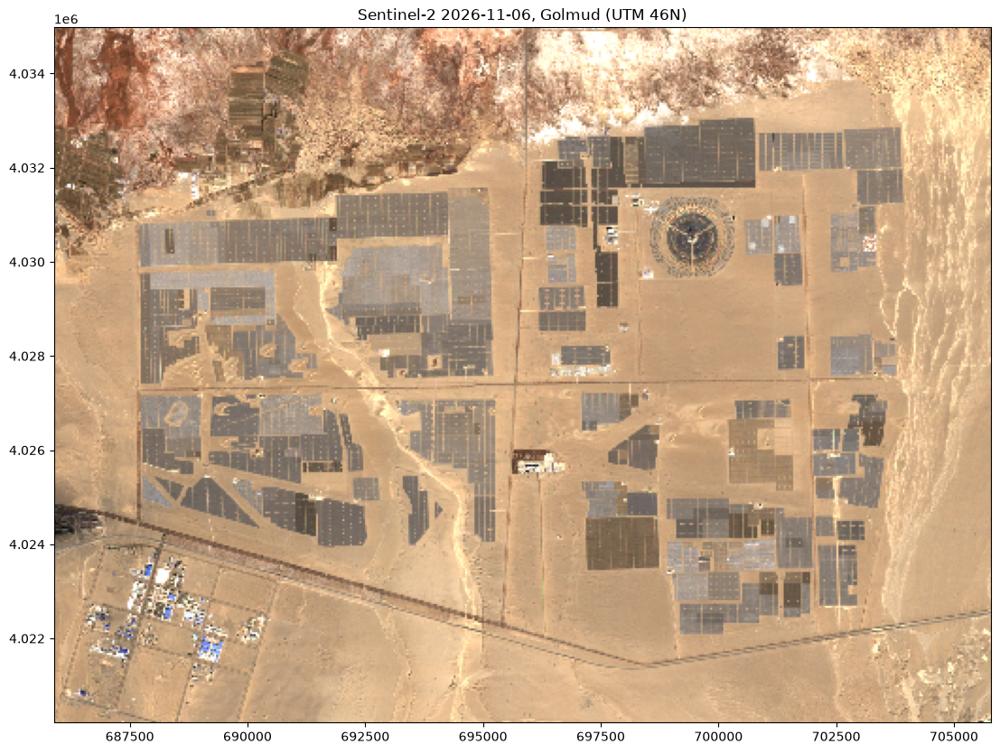

In [3]:
with rasterio.open(raw_scene) as src:
    F = 4
    rgb = src.read([3, 2, 1], out_shape=(3, src.height // F, src.width // F)).astype("float32")
    bounds = src.bounds
    print(f"{src.width} x {src.height} pixels, {src.width * 10 / 1000:.1f} x {src.height * 10 / 1000:.1f} km")

rgb = np.clip((np.moveaxis(rgb, 0, -1) - BASELINE_OFFSET) / 3000, 0, 1)

plt.figure(figsize=(14, 10))
plt.imshow(rgb, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
plt.title(f"Sentinel-2 {SCENE_DAY}, Golmud (UTM 46N)")
plt.show()

In [4]:
if not label_path.exists():
    raise FileNotFoundError(f"Labels not found: {label_path}. Digitise them in QGIS first.")

# Processing baseline 04.00 and later (all scenes from 2022 on): subtract the offset of 1000
scale_to_byte(raw_scene, scene, offset=BASELINE_OFFSET)

geoai.semantic_segmentation(
    input_path=str(scene),
    output_path=str(mask_path),
    model_path=str(MODEL_DIR / MODEL_FILE),
    probability_path=str(probability_path),
    architecture="unet",
    encoder_name="resnet34",
    num_channels=NUM_CHANNELS,
    num_classes=2,
    window_size=384,
    overlap=192,
    batch_size=4,
)

with rasterio.open(mask_path) as src:
    predicted = src.read(1) == 1
    grid_shape, grid_transform, grid_crs = src.shape, src.transform, src.crs
    pixel_area = abs(src.transform.a * src.transform.e)

print(f"Predicted PV area: {predicted.sum() * pixel_area / 1e6:.1f} km²")

  0%|          | 0/70 [00:00<?, ?it/s]

Predicted PV area: 62.7 km²


### Accuracy

The labels are rasterised on the prediction grid after the same geometry repair as in notebook 04. IoU and F1 come from geoai; precision and recall, which geoai does not offer, are counted here.

In [5]:
labels = gpd.read_file(label_path).to_crs(grid_crs)
labels = labels[labels.geometry.notna() & ~labels.geometry.is_empty]
labels["geometry"] = labels.geometry.make_valid()
labels = labels.explode(index_parts=False)
labels = labels[(labels.geom_type == "Polygon") & (labels.area > 0)]

truth = rasterize(labels.geometry, out_shape=grid_shape, transform=grid_transform,
                  fill=0, default_value=1, dtype="uint8").astype(bool)

scores = geoai.calc_segmentation_metrics(truth.astype("uint8"), predicted.astype("uint8"))

true_positive = int((predicted & truth).sum())
false_positive = int((predicted & ~truth).sum())
false_negative = int((~predicted & truth).sum())

metrics = pd.DataFrame([{
    "IoU": float(scores["iou"]),
    "F1": float(scores["f1"]),
    "precision": true_positive / (true_positive + false_positive),
    "recall": true_positive / (true_positive + false_negative),
    "predicted_km2": predicted.sum() * pixel_area / 1e6,
    "labelled_km2": truth.sum() * pixel_area / 1e6,
}], index=[f"{SITE} {SCENE_DAY}"]).round(3)

metrics.to_csv(EVALUATION_DIR / f"metrics_{SITE}_{SCENE_DAY}.csv")

# Talatan for comparison: whole test scene and plants built after 2020 (never seen)
talatan = pd.read_csv(EVALUATION_DIR / "metrics_split_2026-10-06.csv", index_col="part")
print(f"Talatan 2026, whole scene:      IoU {talatan.loc['whole scene', 'IoU']:.3f}")
print(f"Talatan 2026, built after 2020: IoU {talatan.loc['built after 2020 (unseen)', 'IoU']:.3f}")
print(f"Golmud {SCENE_DAY}:             IoU {metrics['IoU'].iloc[0]:.3f}")
metrics

Talatan 2026, whole scene:      IoU 0.903
Talatan 2026, built after 2020: IoU 0.854
Golmud 2026-11-06:             IoU 0.851


,IoU,F1,precision,recall,predicted_km2,labelled_km2
golmud 2026-11-06,0.851,0.92,0.934,0.906,62.742,64.707


### Error Map

Green: predicted and labelled. Red: predicted but not labelled. Blue: labelled but missed.

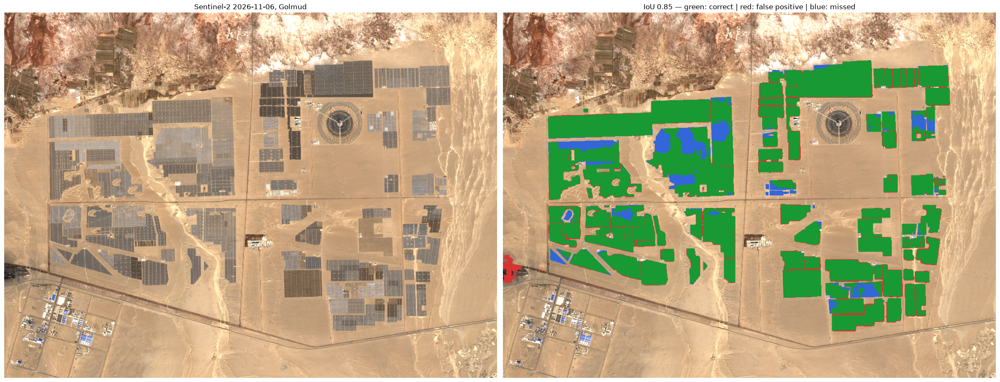

In [6]:
F = 2   # 20 m display pixels

small_predicted, small_truth = predicted[::F, ::F], truth[::F, ::F]

with rasterio.open(scene) as src:
    rgb = src.read([3, 2, 1], out_shape=(3, *small_truth.shape))
rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)   # 191 = reflectance 3000 after scaling

errors = rgb.copy()
errors[small_truth & small_predicted] = [0.10, 0.60, 0.20]   # correct
errors[small_predicted & ~small_truth] = [0.85, 0.20, 0.20]  # false positive
errors[small_truth & ~small_predicted] = [0.20, 0.40, 0.85]  # missed

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
axes[0].imshow(rgb)
axes[0].set_title(f"Sentinel-2 {SCENE_DAY}, Golmud")
axes[1].imshow(errors)
axes[1].set_title(f"IoU {metrics['IoU'].iloc[0]:.2f} — green: correct | red: false positive | blue: missed")
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / f"evaluation_{SITE}_{SCENE_DAY}.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 3: Larger Study Area

The study area above is cut tightly around the labels, with a margin of 1.5 km. In a real application the model would run over a much larger area, where roads, settlements, the town of Golmud and bare surfaces offer many more chances for false positives. The same scene is therefore loaded again with a margin of 10 km and evaluated with the same labels.

Everything outside the labels counts as non-PV. **Before trusting the result, check the false positives in the map below:** if there are other solar plants in the larger area that were not labelled, they count as errors although the model is right, and they would have to be added to the labels.

In [7]:
from shapely.geometry import box

LARGE_MARGIN_M = 10_000   # margin around the labels, in metres

# Larger box: extent of the labels in UTM plus the margin, converted back to WGS84
label_bounds = gpd.read_file(label_path).to_crs(CRS).total_bounds
large_box_utm = box(*label_bounds).buffer(LARGE_MARGIN_M, join_style=2)
GOLMUD_BBOX_LARGE = [round(v, 3) for v in gpd.GeoSeries([large_box_utm], crs=CRS).to_crs("EPSG:4326").total_bounds]
print(f"Large study area: {GOLMUD_BBOX_LARGE}")

raw_large = SCENE_DIR / f"{SITE}_large_{SCENE_DAY}.tif"
scene_large = SCALED_DIR / f"{SITE}_large_{SCENE_DAY}_scaled.tif"
mask_large = PREDICTIONS_DIR / f"prediction_{SITE}_large_{SCENE_DAY}.tif"

found_large = search_scenes(GOLMUD_BBOX_LARGE, SCENE_DAY, SCENE_DAY, max_cloud=100)
if not found_large:
    raise ValueError(f"No scene on {SCENE_DAY} covers the whole large study area")

download_scene(found_large[0]["items"], GOLMUD_BBOX_LARGE, raw_large, crs=CRS)
scale_to_byte(raw_large, scene_large, offset=BASELINE_OFFSET)

geoai.semantic_segmentation(
    input_path=str(scene_large),
    output_path=str(mask_large),
    model_path=str(MODEL_DIR / MODEL_FILE),
    architecture="unet",
    encoder_name="resnet34",
    num_channels=NUM_CHANNELS,
    num_classes=2,
    window_size=384,
    overlap=192,
    batch_size=4,
)

with rasterio.open(mask_large) as src:
    predicted_l = src.read(1) == 1
    shape_l, transform_l = src.shape, src.transform
    print(f"{src.width} x {src.height} pixels, {src.width * 10 / 1000:.1f} x {src.height * 10 / 1000:.1f} km")

Large study area: [np.float64(94.977), np.float64(36.23), np.float64(95.389), np.float64(36.516)]


  0%|          | 0/304 [00:00<?, ?it/s]

3769 x 3257 pixels, 37.7 x 32.6 km


In [8]:
# Labels and the extent of the small study area on the large grid
truth_l = rasterize(labels.to_crs(CRS).geometry, out_shape=shape_l, transform=transform_l,
                    fill=0, default_value=1, dtype="uint8").astype(bool)

with rasterio.open(raw_scene) as src:
    small_extent = box(*src.bounds)
inside_small = rasterize([small_extent], out_shape=shape_l, transform=transform_l,
                         fill=0, default_value=1, dtype="uint8").astype(bool)


def evaluate(pred, ref, name):
    s = geoai.calc_segmentation_metrics(ref.astype("uint8"), pred.astype("uint8"))
    tp, fp, fn = int((pred & ref).sum()), int((pred & ~ref).sum()), int((~pred & ref).sum())
    return {"area": name, "IoU": float(s["iou"]), "F1": float(s["f1"]),
            "precision": tp / (tp + fp), "recall": tp / (tp + fn),
            "predicted_km2": pred.sum() * pixel_area / 1e6, "labelled_km2": ref.sum() * pixel_area / 1e6}


comparison = pd.DataFrame([
    evaluate(predicted, truth, f"small (margin 1.5 km)"),
    evaluate(predicted_l, truth_l, f"large (margin {LARGE_MARGIN_M / 1000:.0f} km)"),
]).set_index("area").round(3)
comparison.to_csv(EVALUATION_DIR / f"metrics_{SITE}_extent_{SCENE_DAY}.csv")

outside_fp = predicted_l & ~truth_l & ~inside_small
print(f"False positives outside the small study area: {outside_fp.sum() * pixel_area / 1e6:.1f} km²")
comparison

False positives outside the small study area: 0.4 km²


,IoU,F1,precision,recall,predicted_km2,labelled_km2
area,,,,,,
small (margin 1.5 km),0.851,0.920,0.934,0.906,62.742,64.707
large (margin 10 km),0.841,0.914,0.927,0.900,62.820,64.707


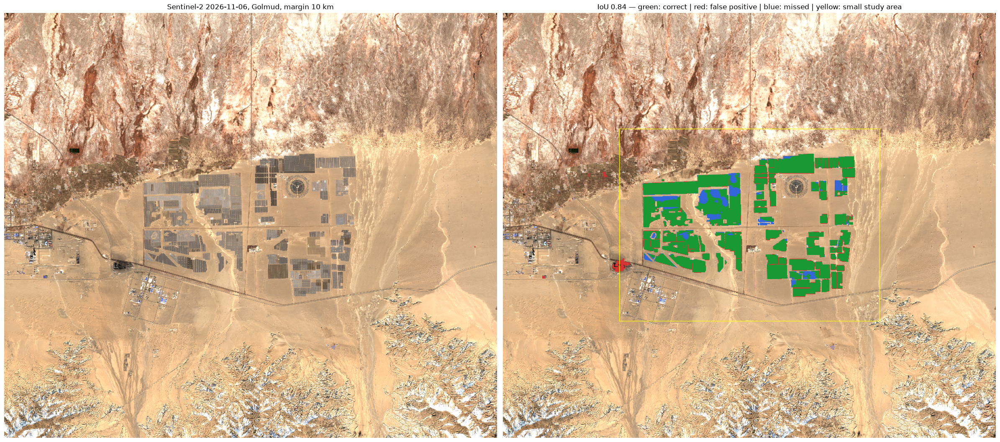

In [9]:
F = 4   # 40 m display pixels

with rasterio.open(scene_large) as src:
    small_shape = (src.height // F, src.width // F)
    rgb = src.read([3, 2, 1], out_shape=(3, *small_shape))
rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)

def shrink(mask):
    return mask[::F, ::F][:small_shape[0], :small_shape[1]]

p, t = shrink(predicted_l), shrink(truth_l)
errors = rgb.copy()
errors[t & p] = [0.10, 0.60, 0.20]    # correct
errors[p & ~t] = [0.85, 0.20, 0.20]   # false positive
errors[t & ~p] = [0.20, 0.40, 0.85]   # missed

# Outline of the small study area
edge = shrink(inside_small)
outline = edge & ~(np.roll(edge, 1, 0) & np.roll(edge, -1, 0) & np.roll(edge, 1, 1) & np.roll(edge, -1, 1))
errors[outline] = [1.0, 1.0, 0.0]

fig, axes = plt.subplots(1, 2, figsize=(24, 11))
axes[0].imshow(rgb)
axes[0].set_title(f"Sentinel-2 {SCENE_DAY}, Golmud, margin {LARGE_MARGIN_M / 1000:.0f} km")
axes[1].imshow(errors)
axes[1].set_title(f"IoU {comparison['IoU'].iloc[1]:.2f} — green: correct | red: false positive | "
                  f"blue: missed | yellow: small study area")
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / f"evaluation_{SITE}_large_{SCENE_DAY}.png", dpi=150, bbox_inches="tight")
plt.show()